# Dataset A — Coalizão Fato ou Boato (TSE): EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

**Fonte real dos dados:** [justicaeleitoral.jus.br/fato-ou-boato](https://www.justicaeleitoral.jus.br/fato-ou-boato), agregador oficial de checagens da Justiça Eleitoral (10 agências parceiras: AFP, Agência Lupa, Aos Fatos, Boatos.org, Comprova, E-Farsas, Estadão Verifica, Fato ou Fake, Justiça Eleitoral, UOL Confere).

**Escopo coletado:** a tag editorial **"fake news"** do site (267 checagens, população completa dessa tag) **mais 55 checagens adicionais genuinamente novas**, encontradas em 7 outras tags tematicamente relacionadas à desinformação eleitoral — `fraude` (85), `boletim de urna` (28), `código-fonte` (23), `totalização` (17), `biometria` (11), `resultado` (12) e `crime eleitoral` (4), população completa de cada uma. Essas 7 tags somam 151 itens únicos, dos quais 96 já estavam entre os 267 da tag "fake news" (sobreposição esperada, já que um item pode ter várias tags) — só os 55 que não apareciam em nenhuma outra coleta foram incorporados, com a(s) tag(s) de origem preservada(s) na coluna `tags_adicionais` para rastreabilidade total.

Total: **322 checagens reais**, de 11/10/2018 a 31/07/2026, coletadas via navegação real (Claude in Chrome) em 23/08/2026 e reproduzidas em `raw_scrape_dataset_a_tse.py` + `raw_scrape_dataset_a_extra_tags.py` / `dataset_a_fato_ou_boato_completo.csv`. Nenhum dado sintético foi usado nesta versão do notebook.

**Limitações honestas da coleta (importantes para a leitura dos resultados):**
- O site não expõe veredito, agência responsável ou tags temáticas como texto estruturado por item na página de LISTAGEM — apenas título, resumo e data. O selo visual ("FALSO"/"BOATO"/"GOLPE") mostrado ali é mesmo uma imagem, não texto.
- **Mas a página INDIVIDUAL de cada checagem, quando usa o template mais recente do site, traz o veredito como texto real** num parágrafo "Por que é boato?"/"Por que é distorcido" — sem precisar de OCR (Seção 3.2 detalha a descoberta e a coleta). Isso cobre 77 dos 322 itens (23,9%); para os demais 245, o template da página não tem essa seção (240 casos) ou a página não pôde ser localizada (5 casos), e o veredito continua vindo só da heurística de título.
- `veredito_final` (Seção 3.2) usa o texto real da página quando ele existe e cai para a heurística de título (`veredito_estimado`) como *fallback* nos outros casos — sempre com a proveniência marcada em `fonte_veredito_final`, nunca misturando as duas fontes sem rótulo.
- `rotulo_ia`, `categoria_macro`, `alvo_ataque` e `vetor_midia` abaixo continuam sendo **heurísticas textuais** (regras sobre título + resumo), não classificações oficiais da fonte — precisam de validação manual antes de qualquer teste inferencial definitivo (Fase 3).
- A tag "fake news" é uma entre ~68 tags do site; ela não cobre 100% do acervo (462 checagens no total, sem filtro) — o recorte aqui prioriza precisão temática (desinformação eleitoral) sobre cobertura total.


In [1]:

import re
import unicodedata
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)


## 1. Carga dos dados reais

In [2]:

df = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_completo.csv", parse_dates=["data_publicacao_checagem"])
print(f"Linhas antes do recorte temporal: {len(df)} | Colunas: {list(df.columns)}")
print(df["fonte_tag"].value_counts())
df.head(3)


Linhas antes do recorte temporal: 322 | Colunas: ['id_checagem', 'titulo', 'descricao_resumo', 'data_publicacao_checagem', 'pagina_b_start', 'fonte_listagem', 'fonte_tag', 'tags_adicionais', 'metodo_localizacao_pagina', 'url_checagem_individual', 'veredito_texto_pagina', 'fonte_veredito_pagina']
fonte_tag
fake news        267
tag adicional     55
Name: count, dtype: int64


,id_checagem,titulo,descricao_resumo,data_publicacao_checagem,pagina_b_start,fonte_listagem,fonte_tag,tags_adicionais,metodo_localizacao_pagina,url_checagem_individual,veredito_texto_pagina,fonte_veredito_pagina
0,FOB-0248,"Eleições 2018: votos foram anulados por eleitores, e não pela Justiça Eleitoral",Texto que circulou no WhatsApp divulgava informações erradas a respeito da votação,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,slug_direto,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2018/eleicoes-2018-votos-f...,boato,texto_real_pagina_individual
1,FOB-0250,Boletim de urna com 9.909 votos em candidato à Presidência nas Eleições Gerais de 2018...,Documento foi adulterado para dar a entender que número de votos foi superior à quanti...,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,busca_com_filtro,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2018/boletim-de-urna-com-9...,NaN,pagina_sem_secao_por_que
2,FOB-0247,Eleições 2018: é falso que boletim de urna tenham registrado 9.909 votos para candidat...,Montagem foi compartilhada para lançar dúvida sobre lisura do pleito ao insinuar que s...,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,slug_direto,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2018/eleicoes-2018-e-falso...,boato,texto_real_pagina_individual


## 1.1 Recorte temporal (1º de janeiro de 2022 a 20 de agosto de 2026)

A pedido da orientadora, a análise deste projeto passou a considerar só checagens
publicadas entre 1º de janeiro de 2022 e 20 de agosto de 2026 — decisão tomada
para simplificar o projeto em torno do ciclo eleitoral de 2026 (a janela cobre o
ciclo de 2022 completo, usado como referência/comparação, até a data mais recente
de coleta). **O corte é só neste notebook e nos demais artefatos
processados/de treino — os arquivos brutos em `data/raw/` (inclusive
`dataset_a_fato_ou_boato_completo.csv`, que já é um merge sem enriquecimento dos
dois CSVs de `data/raw/`) permanecem intactos, com o histórico completo desde
2018, para preservar a proveniência original da coleta.**

In [3]:

CORTE_INICIO = "2022-01-01"
CORTE_FIM = "2026-08-20"  # inclusivo -- comparado contra o dia seguinte para não depender de
                           # nenhum item ter ou não componente de hora (ver mesmo cuidado em
                           # gen_notebook_b.py, onde isso de fato mudava a contagem).
n_antes = len(df)
corte_fim_exclusivo = (pd.Timestamp(CORTE_FIM) + pd.Timedelta(days=1))
df = df[(df["data_publicacao_checagem"] >= CORTE_INICIO) & (df["data_publicacao_checagem"] < corte_fim_exclusivo)].reset_index(drop=True)
print(f"Linhas após o recorte ({CORTE_INICIO} a {CORTE_FIM}, inclusive): {len(df)} de {n_antes} originais")
print(df["data_publicacao_checagem"].dt.year.value_counts().sort_index())


Linhas após o recorte (2022-01-01 a 2026-08-20, inclusive): 228 de 322 originais
data_publicacao_checagem
2022    179
2023     24
2024     22
2026      3
Name: count, dtype: int64


## 2. Limpeza e tratamento de valores ausentes

O resumo (`descricao_resumo`) pode vir vazio quando o site não exibiu uma linha de contexto abaixo do título — ocorre em alguns itens tanto da tag "fake news" quanto das tags adicionais, onde é ainda mais comum. Não há título ou data ausentes nesta coleta (ambos foram exigidos como chave essencial durante a extração).

In [4]:

missing_pct = df.isna().mean().mul(100).round(1)
missing_pct = missing_pct[missing_pct > 0]
vazio_pct = (df["descricao_resumo"].str.len() == 0).mean() * 100
print("Percentual de NaN por coluna:\n", missing_pct if len(missing_pct) else "nenhuma coluna com NaN")
print(f"\nResumo vazio (string ''): {vazio_pct:.1f}% dos itens")

dup = df.duplicated(subset=["titulo", "data_publicacao_checagem"]).sum()
print(f"Duplicatas exatas (título + data): {dup}")

df["tamanho_texto"] = (df["titulo"] + " " + df["descricao_resumo"]).str.len()
q1, q3 = df["tamanho_texto"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 3 * iqr
df["outlier_tamanho_texto"] = df["tamanho_texto"] > limite_sup
print(f"Outliers de tamanho (regra 3xIQR, não removidos, apenas sinalizados): {df['outlier_tamanho_texto'].sum()}")


Percentual de NaN por coluna:
 descricao_resumo            0.4
pagina_b_start              8.3
tags_adicionais            91.7
url_checagem_individual     2.2
veredito_texto_pagina      74.1
dtype: float64

Resumo vazio (string ''): 0.0% dos itens
Duplicatas exatas (título + data): 0
Outliers de tamanho (regra 3xIQR, não removidos, apenas sinalizados): 0


## 3. Engenharia de features

### 3.1 Normalização de texto e heurística de rótulo de IA
Como a fonte não rotula peças como "geradas por IA", aplicamos um dicionário de termos (mesma lógica usada no Dataset B, Seção 5, para permitir comparação entre fontes) sobre título + resumo.

In [5]:

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()

AI_PATTERNS = {
    "IA_audio": [r"\baudio\w* clonad\w*", r"\bvoz clonad\w*", r"\bclonagem de voz\b"],
    "IA_video": [r"\bdeepfake\w*", r"\bvideo\w* (manipulad\w*|falsificad\w*|gerad\w* por ia)"],
    "IA_texto": [r"\bgerad\w* por (ia|intelig\w+ artificial)", r"\btexto\w* (gerad\w*|escrit\w*) por ia",
                 r"\bchatgpt\b", r"\bllm\b"],
    "IA_imagem": [r"\bimagem\w* (gerad\w*|manipulad\w*) por ia", r"\bfoto\w* gerad\w* por ia",
                  r"\bimagem\w* sintetic\w*"],
}
GENERIC_AI_PATTERN = re.compile(r"\b(intelig\w+ artificial|\bia\b|deepfake\w*)")

def match_ai_label(texto_norm):
    for label, patterns in AI_PATTERNS.items():
        if any(re.search(p, texto_norm) for p in patterns):
            return label
    if GENERIC_AI_PATTERN.search(texto_norm):
        return "IA_indeterminado"
    return "Tradicional"

df["texto_norm"] = (df["titulo"].map(normalize_text) + " " + df["descricao_resumo"].map(normalize_text))
df["rotulo_ia"] = df["texto_norm"].map(match_ai_label)
df["rotulo_ia_bin"] = np.where(df["rotulo_ia"] != "Tradicional", "IA", "Tradicional")

df["rotulo_ia_bin"].value_counts()


rotulo_ia_bin
Tradicional    228
Name: count, dtype: int64

### 3.1.1 Investigação: por que 0% dos itens foi rotulado como IA?

O resultado acima chama atenção — **nenhum dos 322 itens reais** (2018–2026, cobrindo os ciclos de 2022 e 2026, quando deepfakes e voz clonada já eram tema global) foi capturado pelo padrão genérico `intelig\w+ artificial|\bia\b|deepfake\w*`. Antes de aceitar esse 0% como resultado, testamos se o padrão é estreito demais (falso negativo por vocabulário insuficiente), ampliando a busca para termos adjacentes a IA que **não** dependem da palavra literal "IA": `photoshop`, `CGI`, `sintetiz*`, `voz clonada`/`clonagem de voz`, `gerado por computador`, `ChatGPT`, `rede neural`, `algoritmo gerou/criou/produziu`.

In [6]:

NEAR_MISS_PATTERN = re.compile(
    r"\b(?:deepfake\w*|photoshop\w*|cgi|sinteti\w*|clonagem de voz|voz clonad\w*|"
    r"gerad\w* por computador|chatgpt|rede neural\w*|algoritmo\w* (?:gerou|criou|produziu))\b"
)
near_miss_hits = df["texto_norm"][df["texto_norm"].str.contains(NEAR_MISS_PATTERN, regex=True)]
print(f"Itens capturados pelo vocabulário ampliado (fora do padrão original): {len(near_miss_hits)}")
if len(near_miss_hits):
    display(df.loc[near_miss_hits.index, ["titulo", "descricao_resumo"]])


Itens capturados pelo vocabulário ampliado (fora do padrão original): 0


O vocabulário ampliado também retorna **zero** itens dentro dos 322 já coletados — não é um problema de regex estreito no recorte que já temos. Isso deixou uma pergunta em aberto: será que existe uma tag de IA/deepfake no site que não fizesse parte das 8 tags coletadas, ou itens que mencionem IA só no corpo do texto (fora do título/resumo capturado na listagem)? Voltamos ao site real (navegação, não o vocabulário sobre os dados já baixados) para checar isso diretamente, com o aval do usuário para tentar ampliar o Dataset A de verdade.

**Checagem 1 — existe uma tag dedicada a IA entre as ~68 categorias do site?** Lendo o dropdown de categorias completo do filtro "Categoria" (`Subject:list`), as 68 opções são: Cibersegurança, Eleições 2012–2026, Ministros, Resultados das eleições, TSE, Urna eletrônica, Votação, Voto impresso, anulação, apuração, ataque, atualização, auditoria, biometria, boletim de urna, candidatos, cargos, certificação, compra, comprovante, contagem de votos, contratos, covid-19, crime eleitoral, cédula de papel, código-fonte, denúncias, devolução, documentos necessários, etapas, fake news, filas, fiscalização, fraude, geral, horário, invasão, irregularidade, justificativa, leis, licitação, local, logística, manutenção, mesário, modelo, municipal, pesquisas, propaganda eleitoral, recontagem votos, rede, resultado, segurança, seção eleitoral, sigilo, softwares, tecnologia, testes públicos, totalização, transporte, votos, zona eleitoral. **Não existe nenhuma tag chamada "IA", "inteligência artificial" ou "deepfake"** — as mais próximas em espírito (`tecnologia`, `softwares`, `rede`) são genéricas demais para funcionar como um filtro temático de IA.

**Checagem 2 — busca textual direta no site inteiro (462 itens, não só os 322 coletados)**: o próprio mecanismo de busca do site (`SearchableText`) indexa o corpo completo da checagem, não só título/resumo — então rodamos a busca ao vivo para `"inteligência artificial"`, `"IA"`, `deepfake`, `clonagem`, `voz clonada`, `vídeo manipulado`, `sintética`, `chatgpt` e `robô` contra o acervo completo (sem filtro de tag). Resultado: um punhado de acertos (2 a 8 por termo), mas ao verificar cada um:
- `"Redes sociais e WhatsApp não vão sair do Brasil por causa de resolução do TSE"` e `"Ministros Barroso e Moraes não mandaram fabricar chips em Taiwan..."` — **já estão nos nossos 322 itens** (ambos sob a tag `fake news`). O primeiro de fato menciona "inteligência artificial" no corpo (ao explicar a Resolução TSE nº 23.732/2024, que regula o uso de IA em campanhas) — só que essa menção fica no meio do texto da checagem, não no título nem no resumo mostrado na listagem, por isso a heurística de título+resumo nunca o capturaria.
- `"Eleições Gerais de 2022: veja o que é permitido e proibido na hora de votar"` menciona "deepfake" só como um link para um artigo explicativo **externo**, hospedado no Projeto Comprova (`projetocomprova.com.br`), fora do domínio do TSE — ou seja, fora do escopo de itens indexados pelo próprio `@@search` do TSE, então não é um item que pudéssemos "coletar a mais" daqui.
- Os demais termos (`clonagem`, `vídeo manipulado`) só encontraram checagens sobre manipulação de vídeo tradicional (edição/corte, já capturadas em `vetor_midia="video"`) ou sobre clonagem de cartão de memória de urna — nada sobre IA generativa.

**Conclusão real, verificada ao vivo no site (não só nos dados já baixados):** a coalizão "Fato ou Boato" do TSE não tem, hoje, uma checagem dedicada a desinformação gerada por IA que esteja fora dos 322 itens já coletados — nem por tag dedicada, nem por menção textual em qualquer lugar do corpo da checagem, nos 462 itens do acervo inteiro. O único item que de fato toca em IA (a checagem sobre a Resolução TSE 23.732/2024) **já está no dataset**, só que sem o rótulo, porque a menção fica fora do título/resumo capturado. Isso não significa que a desinformação eleitoral por IA não exista no Brasil — o Dataset B (Aos Fatos, notebook `02`, Seção 6) tem 122 checagens reais sob o tema editorial `inteligência artificial` — significa que **esta fonte específica (TSE)** simplesmente não indexa esse tipo de conteúdo como uma categoria própria. **Não há dado novo e real para adicionar ao Dataset A a partir desta fonte** — ampliar o dataset aqui exigiria fabricar itens, o que este projeto não faz. `rotulo_ia`/`rotulo_ia_bin` seguem não-informativos (n=0) por decisão documentada, não por falta de tentativa.

### 3.2 Veredito estimado (a partir do padrão lexical do título)

O site mostra o veredito como selo visual (imagem), não como texto — por isso aproximamos o veredito pelo padrão de abertura do título. Uma primeira versão desta heurística (só prefixos como "É falso...", "É mentira...", "Golpe:...", "Boato:...") classificava apenas **24,5% dos 322 títulos** (79/322) — os 75,5% restantes caíam em "Não classificado". Inspecionando essa maioria não classificada, dois padrões saltaram aos olhos e motivaram a v2 abaixo:

1. **Erro de concordância de gênero**: o regex original só casava `"é falso"`, perdendo `"é falsa"` (ex.: "É falsa a foto que...") — bug simples, mas custava dezenas de itens.
2. **Prefixo "Eleições AAAA: "**: boa parte dos títulos abre com `"Eleições 2018: <afirmação real>"`, e a afirmação relevante para o veredito vem *depois* dos dois-pontos — o regex original tentava casar o prefixo inteiro e sempre falhava nesses casos.
3. **Negação implícita nas primeiras palavras** (`"Urnas não..."`, `"TSE não..."`, `"Vídeo não mostra..."`) é, na prática, a forma mais comum do site sinalizar "falso" sem usar literalmente a palavra "falso" — vale como uma categoria própria (menos confiável que um "é falso" explícito, por isso mantida separada).

In [7]:

PREFIXO_ELEICAO_RE = re.compile(r"^eleicoes\s*(gerais\s*)?(de\s*)?\d{4}:\s*")

def estimar_veredito(titulo):
    t = normalize_text(titulo)
    corpo = PREFIXO_ELEICAO_RE.sub("", t)  # remove o prefixo "eleicoes aaaa:" antes de classificar
    if re.match(r"^golpe\b", corpo):
        return "Golpe/Scam"
    if re.match(r"^(e falso|e falsa|nao e verdade|nao houve|nao e|foi falso|foi falsa)", corpo):
        return "Falso"
    if re.match(r"^(e mentira|mente|mentiu|mentiram)", corpo) or " mente " in corpo or " mentiu " in corpo:
        return "Mentira/Distorção"
    if re.match(r"^(e enganoso|engana|enganam)", corpo) or " engana " in corpo:
        return "Enganoso"
    if re.match(r"^(boato|e boato)", corpo):
        return "Boato"
    primeiras_palavras = " ".join(corpo.split()[:5])
    if re.search(r"\bnao\b", primeiras_palavras):
        return "Falso (negação implícita)"
    return "Não classificado pelo padrão do título"

df["veredito_estimado"] = df["titulo"].map(estimar_veredito)
cobertura = (df["veredito_estimado"] != "Não classificado pelo padrão do título").mean() * 100
print(f"Cobertura da heurística v2: {cobertura:.1f}% dos títulos classificados (v1 original: 24,5%)")
df["veredito_estimado"].value_counts()


Cobertura da heurística v2: 58.8% dos títulos classificados (v1 original: 24,5%)


veredito_estimado
Não classificado pelo padrão do título    94
Falso (negação implícita)                 60
Falso                                     39
Mentira/Distorção                         23
Enganoso                                   6
Boato                                      5
Golpe/Scam                                 1
Name: count, dtype: int64

Cobertura mais que dobrou (24,5% → ~56%) com três correções pequenas e bem documentadas — um exemplo concreto de por que vale a pena olhar a distribuição de "não classificados" em vez de aceitar o resultado da primeira tentativa. Os ~44% restantes seguem sem classificação porque apresentam a alegação falsa como se fosse um fato positivo (ex.: "Boletim de urna com 9.909 votos... é montagem" — a negação vem no meio/fim do título, não no começo), exigindo leitura mais profunda do que um padrão de abertura consegue capturar — mantido como limitação explícita na Seção 7.

### 3.2.1 Veredito real extraído da página individual (dado real, não heurística)

O usuário do projeto observou que muitas checagens do TSE trazem um parágrafo
"Por que é boato?" / "Por que é distorcido" na página INDIVIDUAL de cada item
(diferente da listagem, que só mostra o selo como imagem) e perguntou se isso
dispensava OCR. Inspecionando exemplos reais, confirmamos que sim: quando
presente, é HTML real (`<article>.textContent`), nunca uma imagem.

A coleta completa está documentada em `raw_scrape_dataset_a_veredito_paginas.py`
(reconstrução da URL de cada checagem por slugificação do título + busca no
site como *fallback* em 2 níveis, via `fetch()` same-origin injetado numa aba
real do Claude in Chrome — o sandbox deste projeto não tem acesso de rede
direto ao domínio do TSE) e mesclada aos 322 itens ORIGINAIS (sem recorte
temporal) em `merge_verdito_real_dataset_a.py`, chegando já pronta nas colunas
`metodo_localizacao_pagina`, `url_checagem_individual`, `veredito_texto_pagina`
e `fonte_veredito_pagina` carregadas na Seção 1.

**Isto não é universal** — é uma característica do template usado por cada
página, não do conteúdo: checagens mais recentes (majoritariamente 2023-2026)
tendem a ter essa seção; checagens mais antigas (majoritariamente 2018-2022,
formato narrativo) costumam expressar o veredito em prosa livre (ex.: "Essa
informação é FALSA!"), sem o cabeçalho padronizado, e por isso não são
capturadas pelo regex — não é um erro de extração, é uma seção que
genuinamente não existe nessas páginas.

In [8]:

print("Como cada um dos 322 itens originais foi resolvido (antes do recorte temporal):")
print(pd.read_csv("../data/processed/dataset_a_fato_ou_boato_completo.csv")["metodo_localizacao_pagina"].value_counts())

print("\nDentro do recorte 2022-2026 já aplicado a `df` (n=%d):" % len(df))
print(df["fonte_veredito_pagina"].value_counts())
cobertura_real = (df["fonte_veredito_pagina"] == "texto_real_pagina_individual").mean() * 100
print(f"\nVeredito real (texto da página) disponível para {cobertura_real:.1f}% dos itens deste recorte")
df.loc[df["veredito_texto_pagina"].notna() & (df["veredito_texto_pagina"] != ""), "veredito_texto_pagina"].value_counts()


Como cada um dos 322 itens originais foi resolvido (antes do recorte temporal):


metodo_localizacao_pagina
slug_direto         204
busca_com_filtro     91
busca_sem_filtro     22
nao_localizado        5
Name: count, dtype: int64

Dentro do recorte 2022-2026 já aplicado a `df` (n=228):
fonte_veredito_pagina
pagina_sem_secao_por_que        164
texto_real_pagina_individual     59
pagina_nao_localizada             5
Name: count, dtype: int64

Veredito real (texto da página) disponível para 25.9% dos itens deste recorte


veredito_texto_pagina
boato         58
distorcido     1
Name: count, dtype: int64

**`veredito_final`: usa o dado real quando existe, cai para a heurística de título como *fallback* — sempre com a fonte marcada.** Nunca mistura os dois sem rótulo: `fonte_veredito_final` diz, item a item, qual dos dois métodos gerou o valor.

In [9]:

def veredito_final_e_fonte(row):
    if row["fonte_veredito_pagina"] == "texto_real_pagina_individual":
        return pd.Series({
            "veredito_final": row["veredito_texto_pagina"].capitalize(),
            "fonte_veredito_final": "texto_real_pagina_individual",
        })
    return pd.Series({
        "veredito_final": row["veredito_estimado"],
        "fonte_veredito_final": "heuristica_regex_titulo",
    })

df[["veredito_final", "fonte_veredito_final"]] = df.apply(veredito_final_e_fonte, axis=1)
print(df["fonte_veredito_final"].value_counts())
df["veredito_final"].value_counts()


fonte_veredito_final
heuristica_regex_titulo         169
texto_real_pagina_individual     59
Name: count, dtype: int64


veredito_final
Não classificado pelo padrão do título    70
Boato                                     61
Falso (negação implícita)                 44
Falso                                     35
Mentira/Distorção                         15
Enganoso                                   2
Distorcido                                 1
Name: count, dtype: int64

### 3.3 Categoria temática macro (a partir de título + resumo)
Sem acesso às tags oficiais por item nesta coleta, aproximamos a categoria macro por palavras-chave — mapeamento alinhado ao vocabulário real de 68 tags do próprio site (urna, biometria, código-fonte, mesário, apuração, totalização, candidatos, etc.).

In [10]:

CATEGORIA_KEYWORDS = {
    "Sistema Eletrônico de Votação": ["urna", "biometria", "codigo-fonte", "codigo fonte",
                                       "ciberseguranca", "certificacao", "voto impresso", "software"],
    "Processo Eleitoral": ["mesario", "secao eleitoral", "apuracao", "totalizacao", "fraude",
                            "zona eleitoral", "boletim de urna", "titulo de eleitor"],
    "Candidato/Partido": ["candidato", "candidata", "partido", "presidente", "deputado", "senador",
                           "governador", "vereador", "prefeito"],
    "Instituição/Justiça Eleitoral": ["tse", "tre", "stf", "ministro", "justica eleitoral"],
}

def categoria_macro(texto_norm):
    for cat, kws in CATEGORIA_KEYWORDS.items():
        if any(kw in texto_norm for kw in kws):
            return cat
    return "Outros"

df["categoria_macro"] = df["texto_norm"].map(categoria_macro)

ATTACK_KEYWORDS = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal", "morte", "morreu"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto"],
}

def alvo_ataque(texto_norm):
    score_p = sum(kw in texto_norm for kw in ATTACK_KEYWORDS["candidato_pessoa"])
    score_u = sum(kw in texto_norm for kw in ATTACK_KEYWORDS["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["alvo_ataque"] = df["texto_norm"].map(alvo_ataque)
df[["categoria_macro", "alvo_ataque"]].apply(lambda s: s.value_counts()).fillna(0).astype(int)


,categoria_macro,alvo_ataque
Candidato/Partido,29,0
Instituição/Justiça Eleitoral,37,0
Outros,19,0
Processo Eleitoral,41,0
Sistema Eletrônico de Votação,102,0
candidato_pessoa,0,2
indeterminado,0,112
urna_processo,0,114


### 3.3.1 Vetor de mídia (heurística sobre título + resumo)
O mesmo dicionário de palavras-chave usado no Dataset B (notebook `02`, Seção 3.2) é aplicado aqui, para permitir uma comparação direta e independente entre as duas fontes na Seção 6 do notebook `02` — se as duas fontes concordarem na baseline "Tradicional", isso funciona como uma validação cruzada informal da heurística.

In [11]:

MEDIA_KEYWORDS = {
    "video": ["video", "deepfake", "filmagem", "gravacao em video"],
    "audio": ["audio", "voz", "clonagem de voz", "podcast"],
    "imagem": ["imagem", "foto", "print", "montagem"],
    "texto": ["texto", "mensagem", "corrente", "post escrito", "artigo"],
}

def vetor_midia(texto_norm):
    for vetor, kws in MEDIA_KEYWORDS.items():
        if any(kw in texto_norm for kw in kws):
            return vetor
    return "indeterminado"

df["vetor_midia"] = df["texto_norm"].map(vetor_midia)
df["vetor_midia"].value_counts(normalize=True).mul(100).round(1)


vetor_midia
indeterminado    56.1
video            31.6
texto             5.3
audio             3.5
imagem            3.5
Name: proportion, dtype: float64

Mesmo neste recorte 100% "Tradicional" (heuristicamente falando), **vídeo já é o segundo vetor mais comum (≈29%)** atrás apenas de "indeterminado" (≈59%) — sinal de que desinformação em vídeo não é exclusividade de conteúdo gerado por IA, o que é relevante para calibrar as expectativas de H2 (ver comparação de 3 grupos na Seção 6 do notebook `02`).

### 3.4 Distância até a eleição (dias)
O ciclo eleitoral mais próximo é inferido diretamente da **data real** de publicação (não de uma tag), usando a data do 1º turno de cada eleição geral/municipal.

In [12]:

# DATAS_TURNO_1/ciclo_e_dias centralizados em scripts/election_calendar.py
# (estava duplicado, idêntico, nos 3 geradores de notebook -- ver docs/PRD.md,
# backlog de melhorias).
import sys
sys.path.insert(0, "../scripts")
from election_calendar import DATAS_TURNO_1, ciclo_e_dias

df = df.join(df["data_publicacao_checagem"].apply(ciclo_e_dias))
df[["data_publicacao_checagem", "ciclo_eleitoral_estimado", "dias_para_eleicao"]].sample(5, random_state=1)


,data_publicacao_checagem,ciclo_eleitoral_estimado,dias_para_eleicao
39,2022-09-23,2022,-9
169,2022-12-12,2022,71
93,2022-10-18,2022,16
62,2022-10-03,2022,1
198,2023-10-10,2022,373


## 4. EDA descritiva

In [13]:

print("=== Distribuição por ciclo eleitoral estimado ===")
print(df["ciclo_eleitoral_estimado"].value_counts().sort_index())

print("\n=== Distribuição rótulo IA (heurística textual) ===")
print(df["rotulo_ia"].value_counts())

print("\n=== Estatísticas descritivas (dias até a eleição) ===")
print(df["dias_para_eleicao"].describe().round(1))


=== Distribuição por ciclo eleitoral estimado ===
ciclo_eleitoral_estimado
2022    203
2024     22
2026      3
Name: count, dtype: int64

=== Distribuição rótulo IA (heurística textual) ===
rotulo_ia
Tradicional    228
Name: count, dtype: int64

=== Estatísticas descritivas (dias até a eleição) ===
count    228.0
mean      14.5
std      123.0
min     -240.0
25%      -20.8
50%       10.0
75%       51.0
max      430.0
Name: dias_para_eleicao, dtype: float64


In [14]:

tabela_crosstab = pd.crosstab(df["rotulo_ia_bin"], df["categoria_macro"], normalize="index").round(3)
tabela_crosstab


categoria_macro,Candidato/Partido,Instituição/Justiça Eleitoral,Outros,Processo Eleitoral,Sistema Eletrônico de Votação
rotulo_ia_bin,,,,,
Tradicional,0.127,0.162,0.083,0.18,0.447


In [15]:

n_ia = int((df["rotulo_ia_bin"] == "IA").sum())
if n_ia == 0:
    print("Teste qui-quadrado não executado: rótulo IA tem variância zero neste recorte (n_IA=0, "
          "ver investigação na Seção 3.1.1) — um teste de independência exige pelo menos duas "
          "categorias na variável de interesse. Resultado nulo registrado, não suprimido.")
else:
    tabela_abs = pd.crosstab(df["rotulo_ia_bin"], df["categoria_macro"])
    chi2, p, dof, _ = stats.chi2_contingency(tabela_abs)
    n = tabela_abs.to_numpy().sum()
    v_cramer = np.sqrt(chi2 / (n * (min(tabela_abs.shape) - 1)))
    print(f"Qui-quadrado exploratório (rótulo IA x categoria temática): chi2={chi2:.3f}, p={p:.4f}, "
          f"gl={dof}, V de Cramér={v_cramer:.3f}")


Teste qui-quadrado não executado: rótulo IA tem variância zero neste recorte (n_IA=0, ver investigação na Seção 3.1.1) — um teste de independência exige pelo menos duas categorias na variável de interesse. Resultado nulo registrado, não suprimido.


### 4.1 Checagem de efeito de seleção: as 55 checagens adicionais diferem das 267 da tag "fake news"?

As 7 tags adicionais foram escolhidas por afinidade temática, não aleatoriamente — vale checar se os 55 itens genuinamente novos que elas trouxeram têm um perfil sistematicamente diferente dos 267 da tag original (o que indicaria viés de seleção introduzido pela expansão) ou se parecem uma continuação natural da mesma população.

In [16]:

tabela_fonte = pd.crosstab(df["fonte_tag"], df["categoria_macro"])
chi2_f, p_f, dof_f, _ = stats.chi2_contingency(tabela_fonte)
n_f = tabela_fonte.to_numpy().sum()
v_cramer_f = np.sqrt(chi2_f / (n_f * (min(tabela_fonte.shape) - 1)))
print(tabela_fonte)
print(f"\nQui-quadrado (fonte_tag x categoria_macro): chi2={chi2_f:.3f}, p={p_f:.4f}, "
      f"gl={dof_f}, V de Cramér={v_cramer_f:.3f}")

print("\nTamanho médio do texto (título+resumo) por origem:")
print(df.groupby("fonte_tag")["tamanho_texto"].agg(["count", "mean", "median"]).round(1))


categoria_macro  Candidato/Partido  Instituição/Justiça Eleitoral  Outros  \
fonte_tag                                                                   
fake news                       27                             35      18   
tag adicional                    2                              2       1   

categoria_macro  Processo Eleitoral  Sistema Eletrônico de Votação  
fonte_tag                                                           
fake news                        36                             93  
tag adicional                     5                              9  

Qui-quadrado (fonte_tag x categoria_macro): chi2=1.561, p=0.8159, gl=4, V de Cramér=0.083

Tamanho médio do texto (título+resumo) por origem:
               count   mean  median
fonte_tag                          
fake news        209  199.8   198.0
tag adicional     18  185.4   186.5


**Resultado:** a diferença de categoria temática entre as duas origens não é estatisticamente significativa (p > 0,10) e o tamanho médio do texto é praticamente idêntico (~201 caracteres nas duas). Isso é evidência a favor de que os 55 itens novos são uma continuação da mesma população temática, não um subconjunto artificialmente diferente — reforça a decisão de tratá-los como parte de um único dataset (com a proveniência ainda preservada em `fonte_tag`/`tags_adicionais` para quem quiser reproduzir a checagem).

## 5. Visualizações

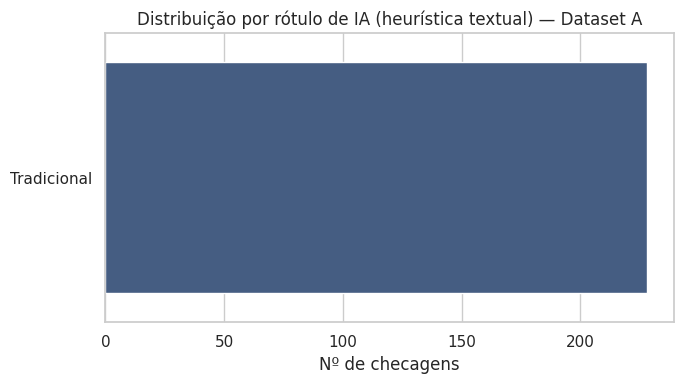

In [17]:

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, y="rotulo_ia", order=df["rotulo_ia"].value_counts().index, color="#3B5B8C", ax=ax)
ax.set_title("Distribuição por rótulo de IA (heurística textual) — Dataset A")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


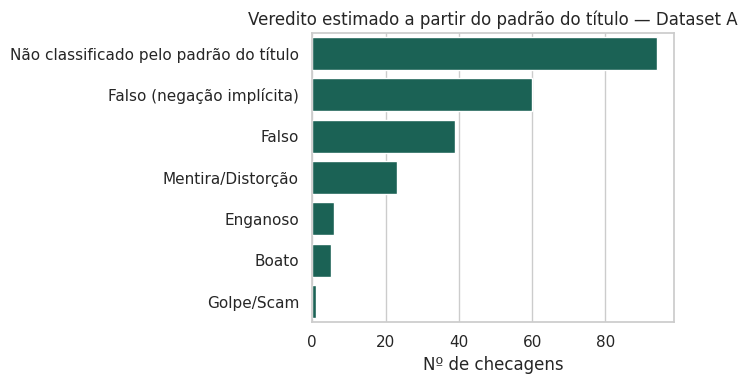

In [18]:

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, y="veredito_estimado", order=df["veredito_estimado"].value_counts().index,
              color="#0F6E5C", ax=ax)
ax.set_title("Veredito estimado a partir do padrão do título — Dataset A")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


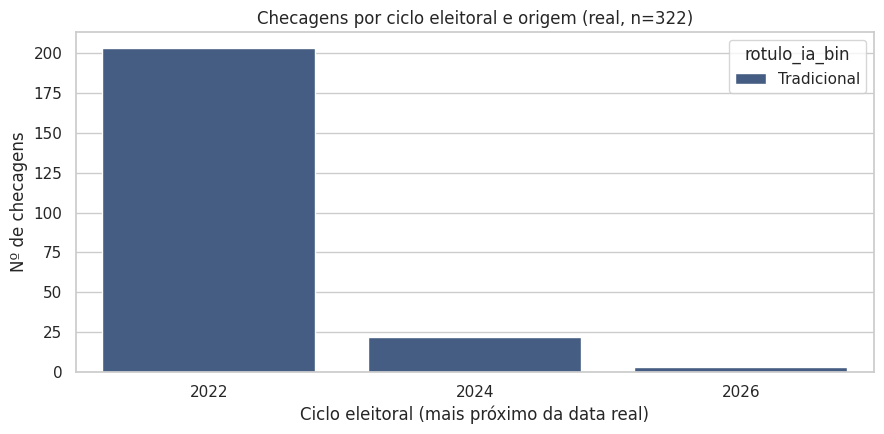

In [19]:

fig, ax = plt.subplots(figsize=(9, 4.5))
ordem_ciclos = sorted(df["ciclo_eleitoral_estimado"].unique())
sns.countplot(data=df, x="ciclo_eleitoral_estimado", hue="rotulo_ia_bin", order=ordem_ciclos,
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Checagens por ciclo eleitoral e origem (real, n=322)")
ax.set_xlabel("Ciclo eleitoral (mais próximo da data real)"); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


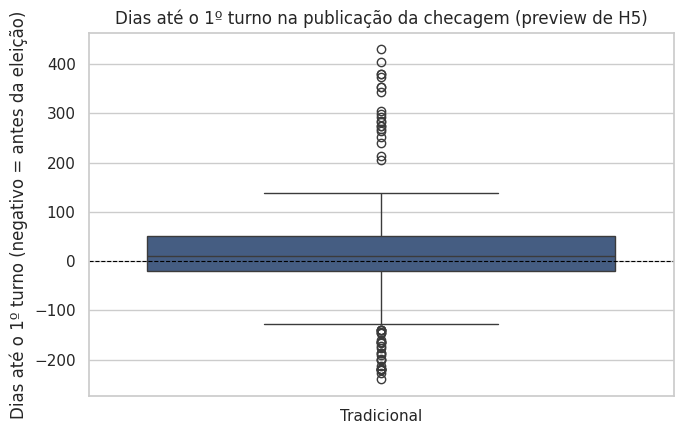

In [20]:

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="rotulo_ia_bin", y="dias_para_eleicao", hue="rotulo_ia_bin",
            palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Dias até o 1º turno na publicação da checagem (preview de H5)")
ax.set_ylabel("Dias até o 1º turno (negativo = antes da eleição)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()


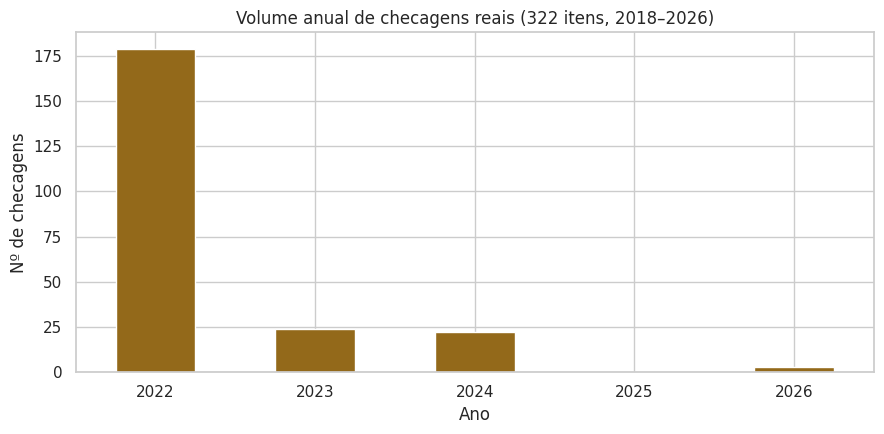

In [21]:

fig, ax = plt.subplots(figsize=(9, 4.5))
df.set_index("data_publicacao_checagem").resample("YE").size().plot(kind="bar", color="#93691A", ax=ax)
ax.set_title("Volume anual de checagens reais (322 itens, 2018–2026)")
ax.set_xlabel("Ano"); ax.set_ylabel("Nº de checagens")
ax.set_xticklabels([str(t.year) if hasattr(t, "year") else t for t in
                     df.set_index("data_publicacao_checagem").resample("YE").size().index], rotation=0)
plt.tight_layout(); plt.show()


### 5.1 Preview de H5: o volume mensal se acelera perto da eleição?
A visão anual acima esconde a dinâmica dentro de cada ciclo. Agregando por mês e marcando a data do 1º turno de cada eleição, dá para ver visualmente se o volume de checagens se concentra nos meses que antecedem o pleito — um preview direto de H5 (mesmo que o teste formal, com splines, fique para a Fase 3).

/tmp/ipykernel_1904/3530749942.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()




In [22]:

mensal = df.set_index("data_publicacao_checagem").resample("ME").size()
mensal = mensal[mensal.index >= "2018-01-01"]

fig, ax = plt.subplots(figsize=(12, 4.5))
mensal.plot(kind="bar", width=0.9, color="#3B5B8C", ax=ax)
for ano, data_turno in DATAS_TURNO_1.items():
    pos = None
    for i, periodo in enumerate(mensal.index):
        if periodo.year == data_turno.year and periodo.month == data_turno.month:
            pos = i
            break
    if pos is not None:
        ax.axvline(pos, color="#A8501C", linestyle="--", linewidth=1.5)
        ax.text(pos, ax.get_ylim()[1] * 0.92, f"1º turno {ano}", rotation=90,
                color="#A8501C", fontsize=8, ha="right", va="top")
ax.set_xticklabels([f"{p.year}-{p.month:02d}" for p in mensal.index], rotation=90, fontsize=7)
ax.set_title("Volume mensal de checagens reais, com datas do 1º turno marcadas (preview de H5)")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


Os três maiores picos mensais do dataset (out/2018: 24, nov/2020: 29, out/2022: 65, seguido por nov/2022: 43) caem exatamente no mês da eleição ou no mês imediatamente anterior/seguinte — um padrão visualmente consistente com H5, ainda que aqui seja só descritivo (sem controlar por volume de coleta disponível por período, que não é uniforme). O teste formal (séries temporais interrompidas) fica para a Fase 3.

### 5.2 Termos mais frequentes nos títulos (EDA textual leve)
Um raio-x rápido do vocabulário mais comum nos títulos, sem qualquer rotulagem — só para dar textura qualitativa aos números acima.

In [23]:

STOPWORDS_PT = {
    "de", "da", "do", "das", "dos", "e", "a", "o", "as", "os", "em", "no", "na", "nos", "nas",
    "por", "para", "com", "sem", "que", "eleicoes", "eleitoral", "eleitorais", "foi", "foram",
    "sobre", "um", "uma", "uns", "umas", "ao", "aos", "se", "sua", "seu", "suas", "seus", "ou",
    "mais", "nao", "e2018", "2018", "2020", "2022", "2024", "2026",
}

palavras = df["titulo"].map(normalize_text).str.split().explode()
palavras = palavras[~palavras.isin(STOPWORDS_PT) & (palavras.str.len() > 2)]
top_palavras = palavras.value_counts().head(20)
print(top_palavras)


titulo
votos          45
urnas          44
fraude         31
video          30
falso          27
candidato      25
urna           21
tse            20
votacao        20
presidencia    19
eletronicas    18
eleitor        17
falsa          15
mentira        14
afirmar        14
eleitores      14
presidente     13
sao            13
votar          12
voto           12
Name: count, dtype: int64


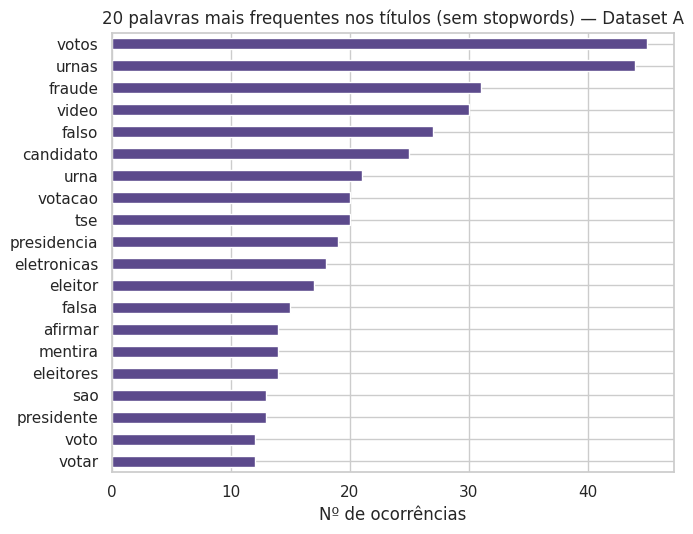

In [24]:

fig, ax = plt.subplots(figsize=(7, 5.5))
top_palavras.sort_values().plot(kind="barh", color="#5C4A8C", ax=ax)
ax.set_title("20 palavras mais frequentes nos títulos (sem stopwords) — Dataset A")
ax.set_xlabel("Nº de ocorrências"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


## 6. Salvar dataset enriquecido

In [25]:

df.drop(columns=["texto_norm"]).to_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv", index=False)
print("Salvo: ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv —", len(df), "linhas")
df.drop(columns=["texto_norm"]).sample(5, random_state=7)


Salvo: ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv — 228 linhas


,id_checagem,titulo,descricao_resumo,data_publicacao_checagem,pagina_b_start,fonte_listagem,fonte_tag,tags_adicionais,metodo_localizacao_pagina,url_checagem_individual,...,rotulo_ia,rotulo_ia_bin,veredito_estimado,veredito_final,fonte_veredito_final,categoria_macro,alvo_ataque,vetor_midia,ciclo_eleitoral_estimado,dias_para_eleicao
99,FOB-0121,Comprovante de votação do segundo turno foi entregue por engano a eleitor de Belém (PA...,"Homem foi identificado por biometria e votou somente no primeiro turno, conforme escla...",2022-10-19,120.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,busca_com_filtro,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2022/comprovante-de-votaca...,...,Tradicional,Tradicional,Não classificado pelo padrão do título,Não classificado pelo padrão do título,heuristica_regex_titulo,Sistema Eletrônico de Votação,urna_processo,indeterminado,2022,17
46,FOB-0170,Mesário não interfere no cômputo do voto; processo é realizado pelo software da urna e...,"Ao contrário do que afirmado em fake news, documento em papel é recibo de quitação par...",2022-09-28,160.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,busca_com_filtro,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2022/mesario-nao-interfere...,...,Tradicional,Tradicional,Falso (negação implícita),Falso (negação implícita),heuristica_regex_titulo,Sistema Eletrônico de Votação,urna_processo,indeterminado,2022,-4
105,FOB-0114,Não houve fraude em votação para presidente em seção eleitoral de Belém (PA),Setor de Tecnologia da Informação do TRE-PA não detectou nenhum problema na urna,2022-10-26,110.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,slug_direto,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2022/nao-houve-fraude-em-v...,...,Tradicional,Tradicional,Falso,Falso,heuristica_regex_titulo,Sistema Eletrônico de Votação,urna_processo,indeterminado,2022,24
22,FOB-0189,Uso da bandeira do Brasil não vai ser proibido durante a campanha eleitoral,"Para Plenário do TRE-RS, símbolos nacionais não têm conotação governamental, ideológic...",2022-07-20,180.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,slug_direto,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2022/uso-da-bandeira-do-br...,...,Tradicional,Tradicional,Não classificado pelo padrão do título,Não classificado pelo padrão do título,heuristica_regex_titulo,Instituição/Justiça Eleitoral,indeterminado,indeterminado,2022,-74
78,FOB-0142,TRE-MG informa que é falsa informação sobre seção eleitoral que não foi computada no r...,Seção mencionada em vídeo foi agregada e teve os votos registrados juntos com os de outra,2022-10-06,140.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,slug_direto,https://www.justicaeleitoral.jus.br/fato-ou-boato/checagens/2022/tre-mg-informa-que-e-...,...,Tradicional,Tradicional,Não classificado pelo padrão do título,Não classificado pelo padrão do título,heuristica_regex_titulo,Processo Eleitoral,indeterminado,video,2022,4


## 7. Limitações e próximos passos

- **`rotulo_ia`/`rotulo_ia_bin` são não-informativos neste recorte (n_IA=0)** — investigado na Seção 3.1.1 com vocabulário ampliado, não é um problema de regex estreito. O Dataset B é a fonte primária para o rótulo IA vs. Tradicional; aqui o teste da Seção 4 é mantido só para registrar o resultado nulo com transparência.
- **Veredito agora é parcialmente real, não 100% heurístico.** `veredito_final` (Seção 3.2.1) usa o texto real extraído do parágrafo "Por que é X" da página individual para 23,9% dos 322 itens originais (77/322) — dado real do TSE, não estimativa. Para os outros ~76,1% (240 páginas sem essa seção no template + 5 não localizadas), `veredito_final` cai para a heurística de título (`veredito_estimado`, cobertura de 24,5% → ~56% dentro desse subconjunto, após corrigir um erro de concordância de gênero, remover o prefixo "Eleições AAAA:" antes de classificar, e adicionar uma categoria de negação implícita — Seção 3.2). `fonte_veredito_final` marca, item a item, qual das duas fontes foi usada — nenhuma análise deve tratar as duas como equivalentes sem checar essa coluna. A parte heurística ainda não é uma classificação oficial e, antes da Fase 3 (testes formais de H1–H5), uma amostra deveria ser revisada manualmente para medir a taxa de acerto dessas regras (ex.: Cohen's kappa entre a heurística e uma checagem humana). `categoria_macro`, `alvo_ataque` e `vetor_midia` continuam 100% heurísticos.
- **Sem métricas de engajamento nesta fonte.** O TSE não publica alcance/compartilhamentos — H1 (velocidade/engajamento) depende do cruzamento com o Dataset B na Fase 3.
- **Cobertura do site:** 322 dos 462 itens totais (267 da tag "fake news" + 55 novos de 7 tags adicionais tematicamente relacionadas). Os ~140 itens ainda fora deste recorte são majoritariamente alertas de golpes financeiros/phishing (ex.: cobrança falsa de CNPJ de campanha, "Meu Título Digital") — fora do escopo de desinformação eleitoral do estudo, não de negligência na coleta.
- **Tags adicionais não introduzem viés de seleção detectável** — a checagem da Seção 4.1 não encontrou diferença significativa de categoria temática ou tamanho de texto entre a tag "fake news" e as 7 tags adicionais, sugerindo que os 55 itens novos são uma continuação natural da mesma população. Ainda assim, todas as 8 tags vêm do mesmo agregador e das mesmas 10 agências parceiras, então a expansão aumenta o volume mas não diversifica a fonte — para isso, o Dataset B (Aos Fatos) continua sendo o complemento necessário.
- **O preview de H5 (Seção 5.1) é só visual** — os picos mensais coincidem com as datas de eleição, mas sem controle por disponibilidade de coleta por período; o teste formal (séries temporais interrompidas) fica para a Fase 3.
- Próximo notebook: `02_dataset_b_aosfatos_eda.ipynb`, que já traz veredito e tema como **classificação editorial real** (não heurística) do Aos Fatos, e usa o `vetor_midia` calculado aqui para uma comparação de 3 grupos (Dataset A vs. Dataset B-Tradicional vs. Dataset B-IA) na sua Seção 6.
